# 04 — Đánh giá và báo cáo

Sau phần hiệu chỉnh ở notebook 03, mô hình, tham số và ngưỡng được giữ cố định để đọc kết quả test. Kết quả gồm accuracy known, AUROC, coverage, risk và tỷ lệ unknown được tự nhận nhầm, báo riêng từng chỉ số. Hồ sơ lô và chứng từ trong các tình huống là dữ liệu mô phỏng, không dùng để kết luận xuất xứ từ ảnh.

Ghi chú cấu hình tham khảo đã lưu: 336px, no TTA, catalog_grouped, relative conformal, nearest-ratio, joint extra-development risk 2%. Tham số thực tế lấy từ `.env`; kernel được khởi động lại khi đổi cấu hình.


## 1. Đọc cấu hình chung `.env`

In [1]:
from pathlib import Path
import sys
sys.dont_write_bytecode = True
nb_dir = Path.cwd() if (Path.cwd() / 'notebook_utils.py').is_file() else Path.cwd() / 'notebooks'
assert (nb_dir / 'notebook_utils.py').is_file(), 'Mở notebook từ thư mục dự án hoặc notebooks.'
sys.path.insert(0, str(nb_dir.resolve()))
from notebook_utils import load_workflow, show_table
run = load_workflow()

## 2. Đánh giá model chính và các kịch bản nghiệp vụ

In [2]:
evaluation_result = run.evaluate()
evaluation_result

Đang chạy evaluate (head)...
C:\Users\user\.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\user\.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\user\.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
[eval] encoder=dinov2_vits14_s336_90f15cb97276985d_proj384_35d5872bc9167e3c_tta0_prototype_hs96w0.3_v1 splits={'protocol': 'known_unknown_70_30_v1', 'n_train_images': 2878, 'n_validation_images': 1887, 'n_known_classes': 17, 'n_train_classes': 17, 'n_novel_classes': 7, 'n_support_images': 34, 'n_calib_images': 1915, 'n_test_images': 1927, 'n_unknown_calib': 0, 'n_unknown_test': 4200, 'n_n

{'closed_set': {'accuracy_all_classes': 0.8188894654903995,
  'macro_f1_all_classes': 0.8183034822496336,
  'macro_f1_with_unknown': 0.6390245813274593,
  'n_test_images': 1927},
 'open_set': {'threshold': 0.8709140938168102,
  'known_recall': 0.8676699532952776,
  'unknown_reject_rate': 0.7028571428571428,
  'false_accept_rate': 0.29714285714285715,
  'auroc': 0.8641173054587689,
  'n_known': 1927,
  'n_unknown': 4200,
  'score': 'energy',
  'distance_baseline': {'threshold': 0.9430068731307983,
   'known_recall': 0.8604047742605085,
   'unknown_reject_rate': 0.7014285714285714,
   'false_accept_rate': 0.2985714285714286,
   'auroc': 0.8632034744359601,
   'n_known': 1927,
   'n_unknown': 4200,
   'fpr_at_95tpr': {'threshold': 1.0514497756958008,
    'tpr': 0.9501816294758693,
    'fpr': 0.6202380952380953}}},
 'scenarios': {'n_passed': 9,
  'n_cases': 12,
  'failed': ['happy_path', 'pending_evidence', 'ticket_switch']},
 'warnings': ['Ngưỡng chỉ được chọn từ known-calib. Khả năng từ 

## 3. So sánh với hai baseline
Hai đối chứng là descriptor cổ điển và DINOv2 không head, dùng cùng split và ngưỡng riêng. Các mô hình không được chọn theo kết quả test.

In [3]:
comparison = run.compare_baselines()
show_table(comparison)

Đang chạy evaluate (classical)...
[eval] encoder=classical2_s128_c8_h16_g3_r32_f8_tta0 splits={'protocol': 'known_unknown_70_30_v1', 'n_train_images': 2878, 'n_validation_images': 1887, 'n_known_classes': 17, 'n_train_classes': 17, 'n_novel_classes': 7, 'n_support_images': 34, 'n_calib_images': 1915, 'n_test_images': 1927, 'n_unknown_calib': 0, 'n_unknown_test': 4200, 'n_novel_support': 35, 'n_novel_query': 836}
Đang chạy evaluate (raw)...
C:\Users\user\.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\user\.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\user\.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is 

model,accuracy_known,macro_f1_known,auroc,coverage_known,risk_known,answered_known,target_met_on_test,unknown_auto_accept
classical,0.14789828749351322,0.14191426461723008,0.49197988484444116,0.0,None,0,False,0.0
raw,0.6113129216398547,0.6402615546519506,0.713549064669978,0.06175402179553711,0.32773109243697474,119,False,0.0033333333333333335
head,0.8188894654903995,0.8183034822496336,0.8641173054587689,0.18214841722885314,0.008547008547008517,351,True,0.005238095238095238


## 4. Xem đường risk–coverage
Đường quét phục vụ phân tích test; điểm vận hành vẫn lấy từ ngưỡng đã fit trên calib.

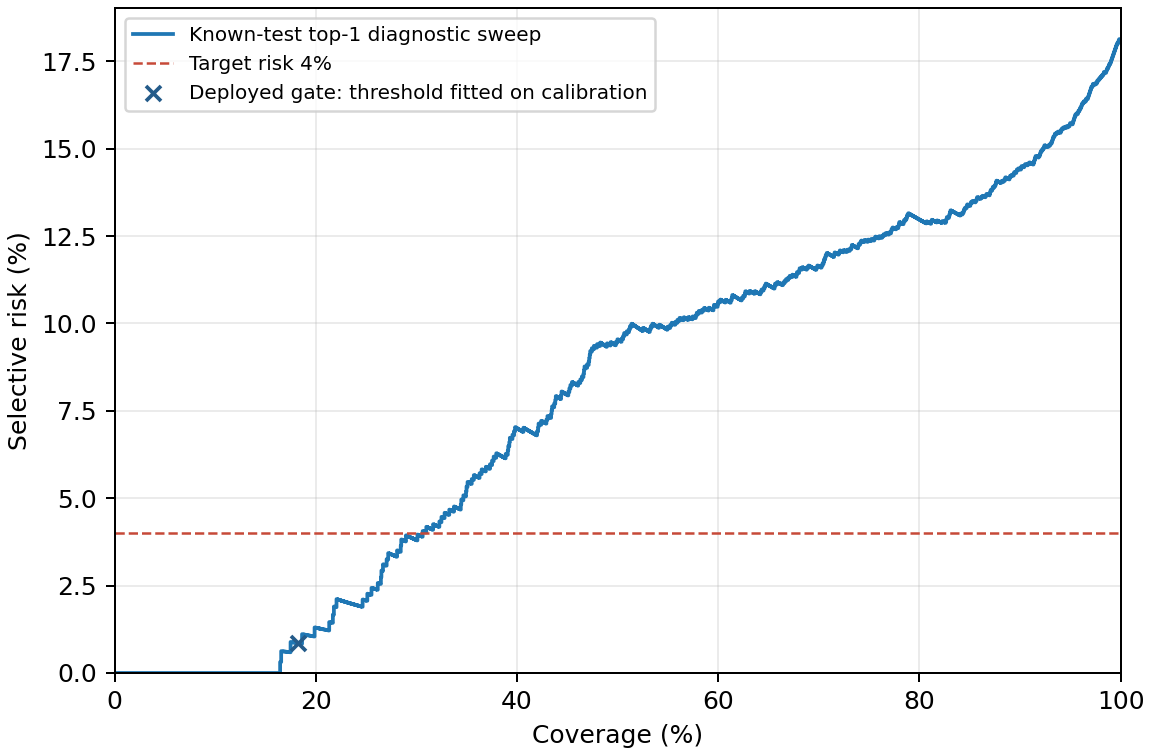

In [4]:
run.plot_risk_coverage()

## 5. Phân tích nhầm lẫn và có/không túi
Trường `packed` lấy từ metadata nguồn, có thể có sai sót nhãn.

In [5]:
show_table(run.error_analysis())

Các cặp nhầm lẫn thường gặp:


true,pred,count
Cà chua hồng,Cà chua tim bò,92
Táo Red Delicious,Táo Spartan,53
Táo Spartan,Táo Ligol,41
Táo Red Delicious,Hành tây tím,32
Táo Ligol,Táo Spartan,17
Cà chua tim bò,Táo Red Delicious,9
Táo Spartan,Cà chua bi vàng,7
Cà chua hồng,Rau xà lách xanh,6
Cà chua tim bò,Táo Ligol,6
Bắp ngô,Cà rốt,5


Có/không túi theo metadata nguồn (packed=1/0):


pool,packed,n,coverage,risk
known,0,957,0.24346917450365727,0.0
known,1,970,0.12164948453608247,0.025423728813559324
unknown,0,2090,0.0066985645933014355,1.0
unknown,1,2110,0.0037914691943127963,1.0


## 6. Kiểm tra audit và lấy đường dẫn báo cáo

In [6]:
print(run.verify_audit())
run.output_paths()

{'valid': True, 'n_entries': 12, 'problems': [], 'head': '274afcf6a4f49f981a0cc7bdabfda707707a12ecb3020db093ecf0458d8cce34'}


{'model': 'D:\\Documents\\retail-provenance-vision-main\\var\\thesis_v4\\projection_head.pt',
 'report': 'var\\thesis_v4\\reports\\20261019T144912_fc6e8261\\evaluation_dinov2_vits14_s336_90f15cb97276985d_proj384_35d5872bc9167e3c_tta0_prototype_hs96w0.3_v1.md',
 'comparison': 'D:\\Documents\\retail-provenance-vision-main\\var\\thesis_v4\\tables\\model_comparison.csv',
 'folder': 'D:\\Documents\\retail-provenance-vision-main\\var\\thesis_v4'}

Mô hình và các tệp đánh giá có thể được sử dụng trong demo. **05_additional_tests.ipynb** cung cấp các phép thử bổ sung cho báo cáo; **06_demo.ipynb** trình bày luồng sử dụng mô hình.